In [1]:
import pandas as pd
import os

# os.chdir(os.path.dirname(os.path.abspath(__file__)))

In [122]:
idb5yr = pd.read_csv('data/idb5yr.csv')

In [168]:
columns = ['POP', 'GEO_ID']
idb5yr[columns]

,POP,GEO_ID
0,6176,W140000WOAD
1,6310,W140000WOAD
2,5866,W140000WOAD
3,5591,W140000WOAD
4,5503,W140000WOAD
...,...,...
253008,52680,W650000WOPK008003004001
253009,52669,W650000WOPK008003004001
253010,52619,W650000WOPK008003004001
253011,52545,W650000WOPK008003004001


In [219]:
country_id = idb5yr[idb5yr['GEO_ID'].str[:3] == 'W14'].sample(12, random_state = 100)
region_id = idb5yr[idb5yr['GEO_ID'].str[:3] != 'W14'].sample(2, random_state = 100)
dup_id = country_id['GEO_ID'].sample(1, random_state=100).iloc[0]
print(dup_id)
dup_rows = country_id[country_id['GEO_ID'] == dup_id].sample(1, random_state=69)
mock = pd.concat([country_id, region_id, dup_rows])
mock_sample = mock.sample(frac=1, random_state=60).reset_index(drop=True)
mock_sample

W140000WOUA


,YR,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,DEATHS,NIM,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_
0,1954,W140000WOKY,264.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2069,W140000WOSG,709.0,12.4,49.4,82.4,82.4,41.2,9.9,2.5,...,78533.0,25000.0,-29161.0,51.2,49.4,53.3,1.047,82.8,20.5,62.3
2,2027,W500000WOBR008082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.039,53.5,41.2,12.3
3,2028,W140000WOXW,5640.0,30.7,160.4,197.5,153.9,89.6,21.5,1.5,...,11057.0,-12271.0,78480.0,22.5,22.3,22.8,1.033,68.2,60.6,7.6
4,2056,W140000WOTM,469930.0,17.8,86.2,120.6,102.6,50.0,12.8,2.8,...,59743.0,-9620.0,21114.0,40.5,39.4,41.7,0.969,62.5,30.0,32.5
5,1986,W140000WOCV,4033.0,89.8,245.1,276.8,251.9,210.2,116.3,16.4,...,3118.0,-5426.0,9897.0,17.2,16.1,18.4,0.888,102.1,90.6,11.5
6,1963,W140000WOUA,579330.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2020,W140000WOBE,30278.0,4.8,34.0,99.6,110.8,48.5,11.6,0.8,...,126850.0,48330.0,-13165.0,41.9,40.9,43.0,0.973,56.6,26.2,30.4
8,1963,W140000WOUA,579330.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1955,W140000WOHK,1073.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [220]:
cc_cn = pd.read_csv('data/countries_codes_and_coordinates.csv')

In [221]:
def rename_column(df, keys, new_keys):
    return df.rename(columns={keys[i]:new_keys[i] for i in range(len(keys))})

In [222]:
geo_code = mock_sample[['YR', 'GEO_ID', 'AREA_KM2']]
nation_code = geo_code[geo_code['GEO_ID'].str[0:3] == 'W14'].reset_index(drop=True)
nation_code = nation_code.copy()
nation_code['ALPHA2'] = nation_code['GEO_ID'].str[9:11]
df = nation_code
cc_cn.replace(r'"', '', regex=True, inplace=True)
cc_cn['Country'] = cc_cn['Country'].str.strip()
cc_cn['Alpha-2 code'] = cc_cn['Alpha-2 code'].str.strip()
cc_cn['Alpha-3 code'] = cc_cn['Alpha-3 code'].str.strip()
alpha2_country_map = cc_cn[['Alpha-2 code', 'Country']].set_index('Alpha-2 code')
df['COUNTRY_NAME'] = df['ALPHA2'].map(alpha2_country_map.to_dict()['Country'])
df['COUNTRY_NAME'] = df['COUNTRY_NAME'].fillna('Palestinian Territory, Occupied')
country_alpha_3_map = cc_cn[['Country', 'Alpha-3 code']].set_index('Country')
df['ALPHA3'] =df['COUNTRY_NAME'].map(country_alpha_3_map.to_dict()['Alpha-3 code'])
df = df.drop('GEO_ID', axis=1)
mock_country = rename_column(df, ['AREA_KM2'], ['AREA'])
mock_country

,YR,AREA,ALPHA2,COUNTRY_NAME,ALPHA3
0,1954,264.0,KY,Cayman Islands,CYM
1,2069,709.0,SG,Singapore,SGP
2,2028,5640.0,XW,"Palestinian Territory, Occupied",PSE
3,2056,469930.0,TM,Turkmenistan,TKM
4,1986,4033.0,CV,Cape Verde,CPV
5,1963,579330.0,UA,Ukraine,UKR
6,2020,30278.0,BE,Belgium,BEL
7,1963,579330.0,UA,Ukraine,UKR
8,1955,1073.0,HK,Hong Kong,HKG
9,2025,109820.0,CU,Cuba,CUB


In [ ]:
from dynaconf import Dynaconf
from etl import CountryETLProcessor, CountryYrETLProcessor, Transformer
from sqlalchemy import create_engine

def build_engine():
    settings = Dynaconf(envvar_prefix="DB", load_dotenv=True)
    return create_engine(settings.ENGINE_URL, echo=False)

engine = build_engine()

transformer = Transformer()
with engine.connect() as conn:
    sql = """select * from country;"""
    country_table = pd.read_sql(sql, conn)
    sql = """select * from country_yr;"""
    country_yr_table = pd.read_sql(sql, conn)
engine.dispose()

In [224]:
columns = mock_country.columns
mock_country = rename_column(mock_country, columns, [column.lower() for column in columns])
mock_country

,yr,area,alpha2,country_name,alpha3
0,1954,264.0,KY,Cayman Islands,CYM
1,2069,709.0,SG,Singapore,SGP
2,2028,5640.0,XW,"Palestinian Territory, Occupied",PSE
3,2056,469930.0,TM,Turkmenistan,TKM
4,1986,4033.0,CV,Cape Verde,CPV
5,1963,579330.0,UA,Ukraine,UKR
6,2020,30278.0,BE,Belgium,BEL
7,1963,579330.0,UA,Ukraine,UKR
8,1955,1073.0,HK,Hong Kong,HKG
9,2025,109820.0,CU,Cuba,CUB


In [274]:
gdp = pd.read_csv('data/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_329227.csv')

In [275]:
mock_gdp = gdp[gdp['Country Code'].isin(['BEL','CAN','CPV','CUB','CYM','HKG','LKA','PSE','SGP','TKM','UKR','WSM'])]
len(mock_gdp)

12

In [276]:
mock_gdp = pd.melt(mock_gdp, id_vars=['Country Name', 'Country Code'], value_vars=[str(year) for year in range(1960, 2025)], var_name='YR', value_name='GDP').dropna()
len(mock_gdp)

602

In [277]:
mock_gdp = mock_gdp.dropna()
len(mock_gdp)

602

In [278]:
mock_gdp = rename_column(mock_gdp, ['YR', 'Country Code'], ['yr', 'alpha3'])
mock_gdp.columns

Index(['Country Name', 'alpha3', 'yr', 'GDP'], dtype='str')

In [279]:
country = pd.DataFrame({
    "country_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "country_name": [
        "Cayman Islands", "Singapore", 
        "Palestinian Territory, Occupied", "Turkmenistan", 
        "Cape Verde", "Ukraine","Belgium", "Hong Kong",
        "Cuba", "Canada", "Sri Lanka", "Samoa"],
    "alpha2": ["KY", "SG", "XW", "TM", "CV", "UA", "BE", "HK", "CU", "CA", "LK", "WS"],
    "alpha3": ["CYM", "SGP", "PSE", "TKM", "CPV", "UKR", "BEL", "HKG", "CUB", "CAN", "LKA", "WSM"],
    "area": [264, 709, 5640, 469930, 4033, 579330, 30278, 1073, 109820, 9093507, 64630, 2821]
})

country_yr = pd.DataFrame({
    "country_yr_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
    "country_id": [1, 2, 3, 4, 5, 6, 7, 6, 8, 9, 10, 11, 12],
    "yr": [1954, 2069, 2028, 2056, 1986, 1963, 2020, 1963, 1955, 2025, 1957, 2086, 2078]
})

In [280]:
alpha3_country_map = country[['country_id', 'alpha3']].set_index('alpha3')
mock_gdp['country_id'] = mock_gdp['alpha3'].map(alpha3_country_map.to_dict()['country_id'])
mock_gdp

,Country Name,alpha3,yr,GDP,country_id
0,Belgium,BEL,1960,1.181062e+10,7
1,Canada,CAN,1960,4.056377e+10,10
5,"Hong Kong SAR, China",HKG,1960,1.320797e+09,8
6,Sri Lanka,LKA,1960,1.409874e+09,11
8,Singapore,SGP,1960,7.047517e+08,2
...,...,...,...,...,...
775,West Bank and Gaza,PSE,2024,1.601690e+10,3
776,Singapore,SGP,2024,5.728770e+11,2
777,Turkmenistan,TKM,2024,4.424945e+10,4
778,Ukraine,UKR,2024,1.908340e+11,6


In [282]:
mock_gdp['yr'] = mock_gdp['yr'].astype(int)
country_yr

,country_yr_id,country_id,yr
0,1,1,1954
1,2,2,2069
2,3,3,2028
3,4,4,2056
4,5,5,1986
5,6,6,1963
6,7,7,2020
7,8,6,1963
8,9,8,1955
9,10,9,2025


In [288]:
mock_gdp[['yr', 'country_id']].merge(
    country_yr, on=['yr', 'country_id'], how='inner'
)

,yr,country_id,country_yr_id
0,1986,5,5
1,2020,7,7


In [295]:
merged_mock_gdp = mock_gdp[['yr', 'country_id', 'GDP']].merge(
    country_yr, on=['yr', 'country_id'], how='inner'
)
merged_mock_gdp
# mock_gdp[(mock_gdp['yr'] == 2020) & (mock_gdp['country_id'] == 7)]

,yr,country_id,GDP,country_yr_id
0,1986,5,1.906512e+08,5
1,2020,7,5.296940e+11,7


In [296]:
combined = ['a', 'b', 'c'] + ['d', 'e']
combined

['a', 'b', 'c', 'd', 'e']

In [244]:
mock_gdp = rename_column(gdp, ['Country Code'], ['alpha3'])
mock_gdp.merge(mock_country, on=['alpha3'], how='inner')

,Country Name,alpha3,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2021,2022,2023,2024,2025,Column1,yr,area,alpha2,country_name
0,Belgium,BEL,GDP (current US$),NY.GDP.MKTP.CD,1.181062e+10,1.256170e+10,1.343683e+10,1.444581e+10,1.616804e+10,1.759778e+10,...,5.985220e+11,5.914740e+11,6.507790e+11,6.709830e+11,7.254660e+11,NaN,2020,30278.0,BE,Belgium
1,Canada,CAN,GDP (current US$),NY.GDP.MKTP.CD,4.056377e+10,4.103819e+10,4.233621e+10,4.514034e+10,4.950366e+10,5.464941e+10,...,2.022380e+12,2.200560e+12,2.196590e+12,2.270080e+12,2.319900e+12,NaN,1957,9093507.0,CA,Canada
2,Cabo Verde,CPV,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2.051843e+09,2.247003e+09,2.504526e+09,2.713722e+09,3.056630e+09,NaN,1986,4033.0,CV,Cape Verde
3,Cuba,CUB,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2025,109820.0,CU,Cuba
4,Cayman Islands,CYM,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,6.060814e+09,6.653516e+09,7.308565e+09,7.765337e+09,NaN,NaN,1954,264.0,KY,Cayman Islands
5,"Hong Kong SAR, China",HKG,GDP (current US$),NY.GDP.MKTP.CD,1.320797e+09,1.383682e+09,1.612346e+09,1.935298e+09,2.206466e+09,2.435079e+09,...,3.689540e+11,3.586740e+11,3.807620e+11,4.083690e+11,4.273100e+11,NaN,1955,1073.0,HK,Hong Kong
6,Sri Lanka,LKA,GDP (current US$),NY.GDP.MKTP.CD,1.409874e+09,1.444328e+09,1.434156e+09,1.240672e+09,1.309748e+09,1.698319e+09,...,8.855670e+10,7.414302e+10,8.408031e+10,9.961611e+10,1.088250e+11,NaN,2086,64630.0,LK,Sri Lanka
7,West Bank and Gaza,PSE,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.810900e+10,1.916550e+10,1.863510e+10,1.601690e+10,1.716710e+10,NaN,2028,5640.0,XW,"Palestinian Territory, Occupied"
8,Singapore,SGP,GDP (current US$),NY.GDP.MKTP.CD,7.047517e+08,7.646298e+08,8.262392e+08,9.176080e+08,8.941533e+08,9.746441e+08,...,4.411110e+11,5.142530e+11,5.111820e+11,5.728770e+11,6.038700e+11,NaN,2069,709.0,SG,Singapore
9,Turkmenistan,TKM,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2.633418e+10,3.758391e+10,3.902021e+10,4.424945e+10,4.982862e+10,NaN,2056,469930.0,TM,Turkmenistan


In [243]:
df = pd.melt(mock_gdp, id_vars=['Country Name', 'alpha3'], value_vars=[str(year) for year in range(1960, 2025)], var_name='YR', value_name='GDP').dropna()
df = df[['YR', 'alpha3', 'GDP']]
intersect_gdp = rename_column(df, ['YR'], ['yr'])
intersect_gdp['yr'] = intersect_gdp['yr'].astype(int)
intersect_gdp.merge(mock_country, on=['yr', 'alpha3'], how='inner')

,yr,alpha3,GDP,area,alpha2,country_name
0,1986,CPV,1.906512e+08,4033.0,CV,Cape Verde
1,2020,BEL,5.296940e+11,30278.0,BE,Belgium


In [208]:
mock_gdp = pd.DataFrame({
    "country_yr_id": [1, 2],
    "gdp": [1.906512e+08, 5.296940e+11]
})
mock_gdp.dtypes

country_yr_id      int64
gdp              float64
dtype: object

In [124]:
idbsingleyear = pd.read_csv('data/idbsingleyear.csv')

In [125]:
idbsingleyear.dtypes

YR        int64
GEO_ID      str
AGE       int64
SEX       int64
POP       int64
dtype: object

In [126]:
idbsingleyear[(idbsingleyear['SEX'] == 1) & (idbsingleyear['GEO_ID'] == 'W140000WOAD') & (idbsingleyear['YR'] == 1990)]['POP'].sum()

np.int64(27865)

In [127]:
idb5yr[(idb5yr['GEO_ID'] == 'W140000WOAD') & (idb5yr['YR'] == 1990)]['MPOP']

40    27865.0
Name: MPOP, dtype: float64

In [128]:
idb5yr.columns

Index(['YR', 'GEO_ID', 'AREA_KM2', 'ASFR15_19', 'ASFR20_24', 'ASFR25_29',
       'ASFR30_34', 'ASFR35_39', 'ASFR40_44', 'ASFR45_49',
       ...
       'DEATHS', 'NIM', 'NATINCR', 'MEDAGE', 'MEDAGE_M', 'MEDAGE_F',
       'SEXRATIO', 'DEPND', 'DEPND0_14', 'DEPND65_'],
      dtype='str', length=115)

In [129]:
idb5yr['GEO_ID'].unique()

<StringArray>
[            'W140000WOAD',             'W140000WOAE',
             'W140000WOAF',             'W140000WOAG',
             'W140000WOAI',             'W140000WOAL',
             'W140000WOAM',             'W140000WOAO',
             'W140000WOAR',             'W140000WOAS',
 ...
 'W650000WOPK008002001001', 'W650000WOPK008002001002',
 'W650000WOPK008002002001', 'W650000WOPK008003001001',
 'W650000WOPK008003001002', 'W650000WOPK008003001003',
 'W650000WOPK008003002001', 'W650000WOPK008003002002',
 'W650000WOPK008003003001', 'W650000WOPK008003004001']
Length: 13898, dtype: str

In [130]:
idb5yr_nation = idb5yr[idb5yr['GEO_ID'].str[0:3] == 'W14'].reset_index(drop=True)

In [131]:
idb5yr_nation.head()

,YR,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,DEATHS,NIM,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_
0,1950,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1951,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1952,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1953,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1954,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [132]:
idb5yr_nation['GEO_ID'].unique()

<StringArray>
['W140000WOAD', 'W140000WOAE', 'W140000WOAF', 'W140000WOAG', 'W140000WOAI',
 'W140000WOAL', 'W140000WOAM', 'W140000WOAO', 'W140000WOAR', 'W140000WOAS',
 ...
 'W140000WOVU', 'W140000WOWF', 'W140000WOWS', 'W140000WOXG', 'W140000WOXK',
 'W140000WOXW', 'W140000WOYE', 'W140000WOZA', 'W140000WOZM', 'W140000WOZW']
Length: 227, dtype: str

In [133]:
idb5yr_nation['ALPHA2_CODE'] = idb5yr_nation['GEO_ID'].str[9:11]
idb5yr_nation['ALPHA2_CODE'].unique()

/tmp/ipykernel_23808/3237582330.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  idb5yr_nation['ALPHA2_CODE'] = idb5yr_nation['GEO_ID'].str[9:11]


<StringArray>
['AD', 'AE', 'AF', 'AG', 'AI', 'AL', 'AM', 'AO', 'AR', 'AS',
 ...
 'VU', 'WF', 'WS', 'XG', 'XK', 'XW', 'YE', 'ZA', 'ZM', 'ZW']
Length: 227, dtype: str

In [134]:
idb5yr_nation.head()

,YR,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,NIM,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_,ALPHA2_CODE
0,1950,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
1,1951,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
2,1952,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
3,1953,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
4,1954,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD


In [136]:
alpha2_country_map = country_table[['country_id', 'alpha2']].set_index('alpha2')
idb5yr_nation['COUNTRY_ID'] = idb5yr_nation['ALPHA2_CODE'].map(alpha2_country_map.to_dict()['country_id'])
idb5yr_nation[['YR', 'COUNTRY_ID']].head()
idb5yr_nation.dtypes

/tmp/ipykernel_23808/1257292303.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  idb5yr_nation['COUNTRY_ID'] = idb5yr_nation['ALPHA2_CODE'].map(alpha2_country_map.to_dict()['country_id'])


YR               int64
GEO_ID             str
AREA_KM2       float64
ASFR15_19      float64
ASFR20_24      float64
                ...   
DEPND          float64
DEPND0_14      float64
DEPND65_       float64
ALPHA2_CODE        str
COUNTRY_ID       int64
Length: 117, dtype: object

In [138]:
country_yr_table.head()

,country_yr_id,country_id,yr
0,1,230,1950
1,2,230,1951
2,3,230,1952
3,4,230,1953
4,5,230,1954


In [139]:
ci_yr_cy_map = country_yr_table.set_index(['yr', 'country_id'])

In [140]:
country_yr_table[['yr', 'country_id', 'country_yr_id']]

,yr,country_id,country_yr_id
0,1950,230,1
1,1951,230,2
2,1952,230,3
3,1953,230,4
4,1954,230,5
...,...,...,...
34272,2096,458,34273
34273,2097,458,34274
34274,2098,458,34275
34275,2099,458,34276


In [164]:
# country_yr_table['COUNTRY_YR'].head()
temp = idb5yr_nation.copy()
temp = temp.rename(columns={"YR":"yr", "COUNTRY_ID":"country_id"})

In [165]:
temp.head()

,yr,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_,ALPHA2_CODE,country_id
0,1950,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,230
1,1951,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,230
2,1952,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,230
3,1953,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,230
4,1954,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,230


In [166]:
temp['COUNTRY_YR_ID'] = temp[['yr', 'country_id']].merge(country_yr_table, on=['yr', 'country_id'], how='left')['country_yr_id']
# temp['COUNTRY_YR_ID'] = merged.values()
temp['COUNTRY_YR_ID'].dtype

dtype('int64')

In [14]:
geo_code = idb5yr_nation[['GEO_ID', 'AREA_KM2']]
nation_code = geo_code[geo_code['GEO_ID'].str[0:3] == 'W14']
nation_code['ALPHA2'] = nation_code['GEO_ID'].str[9:11]

In [15]:
country_info = idb5yr_nation[['ALPHA2_CODE', 'AREA_KM2']].drop_duplicates().reset_index(drop=True)
country_info.head()

,ALPHA2_CODE,AREA_KM2
0,AD,468.0
1,AE,71024.0
2,AF,652230.0
3,AG,443.0
4,AI,91.0


In [16]:
cc_cn = pd.read_csv('data/countries_codes_and_coordinates.csv')
cc_cn.replace(r'"', '', regex=True, inplace=True)
cc_cn['Country'] = cc_cn['Country'].str.strip()
cc_cn['Alpha-2 code'] = cc_cn['Alpha-2 code'].str.strip()
cc_cn['Alpha-3 code'] = cc_cn['Alpha-3 code'].str.strip()

In [17]:
cc_cn.head()

,Country,Alpha-2 code,Alpha-3 code,Numeric code,Latitude (average),Longitude (average)
0,Afghanistan,AF,AFG,4,33,65
1,Åland Islands,AX,ALA,248,60.116667,19.9
2,Albania,AL,ALB,8,41,20
3,Algeria,DZ,DZA,12,28,3
4,American Samoa,AS,ASM,16,-14.3333,-170


In [18]:
alpha2_country_map = cc_cn[['Alpha-2 code', 'Country']].set_index('Alpha-2 code')
alpha2_country_map.to_dict()['Country']

{'AF': 'Afghanistan',
 'AX': 'Åland Islands',
 'AL': 'Albania',
 'DZ': 'Algeria',
 'AS': 'American Samoa',
 'AD': 'Andorra',
 'AO': 'Angola',
 'AI': 'Anguilla',
 'AQ': 'Antarctica',
 'AG': 'Antigua and Barbuda',
 'AR': 'Argentina',
 'AM': 'Armenia',
 'AW': 'Aruba',
 'AU': 'Australia',
 'AT': 'Austria',
 'AZ': 'Azerbaijan',
 'BS': 'Bahamas',
 'BH': 'Bahrain',
 'BD': 'Bangladesh',
 'BB': 'Barbados',
 'BY': 'Belarus',
 'BE': 'Belgium',
 'BZ': 'Belize',
 'BJ': 'Benin',
 'BM': 'Bermuda',
 'BT': 'Bhutan',
 'BO': 'Bolivia',
 'BQ': 'Bonaire, Sint Eustatius and Saba',
 'BA': 'Bosnia and Herzegovina',
 'BW': 'Botswana',
 'BV': 'Bouvet Island',
 'BR': 'Brazil',
 'IO': 'British Indian Ocean Territory',
 'BN': 'Brunei',
 'BG': 'Bulgaria',
 'BF': 'Burkina Faso',
 'MM': 'Myanmar',
 'BI': 'Burundi',
 'KH': 'Cambodia',
 'CM': 'Cameroon',
 'CA': 'Canada',
 'CV': 'Cape Verde',
 'KY': 'Cayman Islands',
 'CF': 'Central African Republic',
 'TD': 'Chad',
 'CL': 'Chile',
 'CN': 'China',
 'CX': 'Christmas Isla

In [19]:
country_info['COUNTRY_NAME'] =country_info['ALPHA2_CODE'].map(alpha2_country_map.to_dict()['Country'])
country_info.head()

,ALPHA2_CODE,AREA_KM2,COUNTRY_NAME
0,AD,468.0,Andorra
1,AE,71024.0,United Arab Emirates
2,AF,652230.0,Afghanistan
3,AG,443.0,Antigua and Barbuda
4,AI,91.0,Anguilla


In [20]:
len(country_info['ALPHA2_CODE'].head(1).item())

2

In [21]:
country_info[country_info['COUNTRY_NAME'].isna()]['ALPHA2_CODE']

222    XG
224    XW
Name: ALPHA2_CODE, dtype: str

In [22]:
country_info['COUNTRY_NAME'] = country_info['COUNTRY_NAME'].fillna('Palestinian Territory, Occupied')
country_info[country_info['COUNTRY_NAME'].isna()]['ALPHA2_CODE']

Series([], Name: ALPHA2_CODE, dtype: str)

In [23]:
country_info['COUNTRY_NAME'].isna().any()

np.False_

In [24]:
country_info[country_info['COUNTRY_NAME'] == 'Palestinian Territory, Occupied']

,ALPHA2_CODE,AREA_KM2,COUNTRY_NAME
222,XG,360.0,"Palestinian Territory, Occupied"
224,XW,5640.0,"Palestinian Territory, Occupied"


In [25]:
columns = country_info.columns
columns

Index(['ALPHA2_CODE', 'AREA_KM2', 'COUNTRY_NAME'], dtype='str')

In [26]:
country_alpha_3_map = cc_cn[['Country', 'Alpha-3 code']].set_index('Country')
country_alpha_3_map.to_dict()['Alpha-3 code']

{'Afghanistan': 'AFG',
 'Åland Islands': 'ALA',
 'Albania': 'ALB',
 'Algeria': 'DZA',
 'American Samoa': 'ASM',
 'Andorra': 'AND',
 'Angola': 'AGO',
 'Anguilla': 'AIA',
 'Antarctica': 'ATA',
 'Antigua and Barbuda': 'ATG',
 'Argentina': 'ARG',
 'Armenia': 'ARM',
 'Aruba': 'ABW',
 'Australia': 'AUS',
 'Austria': 'AUT',
 'Azerbaijan': 'AZE',
 'Bahamas': 'BHS',
 'Bahrain': 'BHR',
 'Bangladesh': 'BGD',
 'Barbados': 'BRB',
 'Belarus': 'BLR',
 'Belgium': 'BEL',
 'Belize': 'BLZ',
 'Benin': 'BEN',
 'Bermuda': 'BMU',
 'Bhutan': 'BTN',
 'Bolivia, Plurinational State of': 'BOL',
 'Bolivia': 'BOL',
 'Bonaire, Sint Eustatius and Saba': 'BES',
 'Bosnia and Herzegovina': 'BIH',
 'Botswana': 'BWA',
 'Bouvet Island': 'BVT',
 'Brazil': 'BRA',
 'British Indian Ocean Territory': 'IOT',
 'Brunei Darussalam': 'BRN',
 'Brunei': 'BRN',
 'Bulgaria': 'BGR',
 'Burkina Faso': 'BFA',
 'Burma': 'MMR',
 'Burundi': 'BDI',
 'Cambodia': 'KHM',
 'Cameroon': 'CMR',
 'Canada': 'CAN',
 'Cape Verde': 'CPV',
 'Cayman Islands'

In [27]:
country_info['ALPHA3_CODE'] =country_info['COUNTRY_NAME'].map(country_alpha_3_map.to_dict()['Alpha-3 code'])
country_info.head()

,ALPHA2_CODE,AREA_KM2,COUNTRY_NAME,ALPHA3_CODE
0,AD,468.0,Andorra,AND
1,AE,71024.0,United Arab Emirates,ARE
2,AF,652230.0,Afghanistan,AFG
3,AG,443.0,Antigua and Barbuda,ATG
4,AI,91.0,Anguilla,AIA


In [28]:
keys = country_info.columns
new_keys = [column.lower() for column in country_info.columns]

In [29]:
country_info.rename(columns={keys[i]:new_keys[i] for i in range(len(keys))})

,alpha2_code,area_km2,country_name,alpha3_code
0,AD,468.0,Andorra,AND
1,AE,71024.0,United Arab Emirates,ARE
2,AF,652230.0,Afghanistan,AFG
3,AG,443.0,Antigua and Barbuda,ATG
4,AI,91.0,Anguilla,AIA
...,...,...,...,...
224,XW,5640.0,"Palestinian Territory, Occupied",PSE
225,YE,527968.0,Yemen,YEM
226,ZA,1214470.0,South Africa,ZAF
227,ZM,743398.0,Zambia,ZMB


In [30]:
idb5yr_nation.head(5)

,YR,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,NIM,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_,ALPHA2_CODE
0,1950,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
1,1951,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
2,1952,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
3,1953,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD
4,1954,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD


In [31]:
population_data = idb5yr_nation[['YR', 'GEO_ID', 'AREA_KM2', 'POP_DENS', 'POP']]
population_data.head(5)

,YR,GEO_ID,AREA_KM2,POP_DENS,POP
0,1950,W140000WOAD,468.0,13.2,6176
1,1951,W140000WOAD,468.0,13.5,6310
2,1952,W140000WOAD,468.0,12.5,5866
3,1953,W140000WOAD,468.0,11.9,5591
4,1954,W140000WOAD,468.0,11.8,5503


In [32]:
population_data['POP_DENS'].max()

np.float64(21145.5)

In [33]:
general_data = idb5yr_nation[['YR', 'GEO_ID', 'NATINCR', 'TFR', 'DEATHS', 'NIM', 'SEXRATIO']]
general_data.dropna(inplace=True)
general_data.head(5)

,YR,GEO_ID,NATINCR,TFR,DEATHS,NIM,SEXRATIO
40,1990,W140000WOAD,334.0,1.2940,294.0,2976.0,1.120
41,1991,W140000WOAD,344.0,1.3171,334.0,3802.0,1.116
42,1992,W140000WOAD,392.0,1.3414,337.0,1957.0,1.111
43,1993,W140000WOAD,398.0,1.2660,325.0,2928.0,1.108
44,1994,W140000WOAD,420.0,1.2083,284.0,-1211.0,1.106


In [34]:
general_data['NIM'] = general_data['NIM'].astype(int)
general_data['DEATHS'] = general_data['DEATHS'].astype(int)
general_data['NATINCR'] = general_data['NATINCR'].astype(int)
general_data.dtypes

YR            int64
GEO_ID          str
NATINCR       int64
TFR         float64
DEATHS        int64
NIM           int64
SEXRATIO    float64
dtype: object

In [35]:
baby_data = idb5yr_nation[['YR', 'GEO_ID', 'SRB', 'IMR', 'E0', 'BIRTHS']]
baby_data.dropna(inplace=True)
baby_data.head(5)

,YR,GEO_ID,SRB,IMR,E0,BIRTHS
40,1990,W140000WOAD,1.13,5.85,79.48,628.0
41,1991,W140000WOAD,0.92,6.83,78.64,678.0
42,1992,W140000WOAD,1.08,6.94,78.34,729.0
43,1993,W140000WOAD,0.98,6.46,79.03,723.0
44,1994,W140000WOAD,1.21,5.20,80.46,704.0


In [36]:
baby_data['BIRTHS'] = baby_data['BIRTHS'].astype(int)
baby_data.dtypes

YR          int64
GEO_ID        str
SRB       float64
IMR       float64
E0        float64
BIRTHS      int64
dtype: object

In [37]:
age_data = idb5yr_nation[['YR', 'GEO_ID']]
age_data.head(5)

,YR,GEO_ID
0,1950,W140000WOAD
1,1951,W140000WOAD
2,1952,W140000WOAD
3,1953,W140000WOAD
4,1954,W140000WOAD


In [38]:
age_data['POP_YOUNG'] = idb5yr_nation[['POP0_4', 'POP5_9', 'POP10_14', 'POP15_19', 'POP20_24', 'POP25_29']].sum(axis=1)
age_data['POP_MIDDLE'] = idb5yr_nation[['POP30_34', 'POP35_39', 'POP40_44', 'POP45_49', 'POP50_54', 'POP55_59']].sum(axis=1)
age_data['POP_OLD'] = idb5yr_nation[['POP60_64', 'POP65_69', 'POP70_74', 'POP75_79', 'POP80_84', 'POP85_89', 'POP90_94', 'POP95_99', 'POP100_']].sum(axis=1)
age_data['BIRTHS_YOUNG'] = idb5yr_nation[['BIRTHS15_19', 'BIRTHS20_24', 'BIRTHS25_29']].sum(axis=1)
age_data['BIRTHS_MIDDLE'] = idb5yr_nation[['BIRTHS30_34', 'BIRTHS35_39', 'BIRTHS40_44', 'BIRTHS45_49']].sum(axis=1)
age_data = age_data[['YR', 'GEO_ID', 'POP_YOUNG', 'POP_MIDDLE', 'POP_OLD', 'BIRTHS_YOUNG', 'BIRTHS_MIDDLE']]
age_data = age_data[age_data['POP_YOUNG'] > 0]
age_data = age_data[age_data['POP_MIDDLE'] > 0]
age_data = age_data[age_data['POP_OLD'] > 0]
age_data.head(5)

,YR,GEO_ID,POP_YOUNG,POP_MIDDLE,POP_OLD,BIRTHS_YOUNG,BIRTHS_MIDDLE
40,1990,W140000WOAD,23169.0,22264.0,7314.0,323.0,305.0
41,1991,W140000WOAD,25440.0,23352.0,7683.0,350.0,328.0
42,1992,W140000WOAD,27240.0,24453.0,8029.0,377.0,352.0
43,1993,W140000WOAD,28577.0,25622.0,8360.0,371.0,352.0
44,1994,W140000WOAD,28605.0,26587.0,8634.0,356.0,348.0


In [39]:
gdp = pd.read_csv('data/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_329227.csv')
cc_cn = pd.read_csv('data/countries_codes_and_coordinates.csv')
cc_cn.replace(r'"', '', regex=True, inplace=True)
cc_cn['Alpha-3 code'] = cc_cn['Alpha-3 code'].str.strip()
cc_cn['Alpha-2 code'] = cc_cn['Alpha-2 code'].str.strip()

In [40]:
alpha3_2_map = cc_cn[['Alpha-3 code', 'Alpha-2 code']].set_index('Alpha-3 code')
alpha3_2_map.to_dict()

{'Alpha-2 code': {'AFG': 'AF',
  'ALA': 'AX',
  'ALB': 'AL',
  'DZA': 'DZ',
  'ASM': 'AS',
  'AND': 'AD',
  'AGO': 'AO',
  'AIA': 'AI',
  'ATA': 'AQ',
  'ATG': 'AG',
  'ARG': 'AR',
  'ARM': 'AM',
  'ABW': 'AW',
  'AUS': 'AU',
  'AUT': 'AT',
  'AZE': 'AZ',
  'BHS': 'BS',
  'BHR': 'BH',
  'BGD': 'BD',
  'BRB': 'BB',
  'BLR': 'BY',
  'BEL': 'BE',
  'BLZ': 'BZ',
  'BEN': 'BJ',
  'BMU': 'BM',
  'BTN': 'BT',
  'BOL': 'BO',
  'BES': 'BQ',
  'BIH': 'BA',
  'BWA': 'BW',
  'BVT': 'BV',
  'BRA': 'BR',
  'IOT': 'IO',
  'BRN': 'BN',
  'BGR': 'BG',
  'BFA': 'BF',
  'MMR': 'MM',
  'BDI': 'BI',
  'KHM': 'KH',
  'CMR': 'CM',
  'CAN': 'CA',
  'CPV': 'CV',
  'CYM': 'KY',
  'CAF': 'CF',
  'TCD': 'TD',
  'CHL': 'CL',
  'CHN': 'CN',
  'CXR': 'CX',
  'CCK': 'CC',
  'COL': 'CO',
  'COM': 'KM',
  'COD': 'CD',
  'COG': 'CG',
  'COK': 'CK',
  'CRI': 'CR',
  'CIV': 'CI',
  'HRV': 'HR',
  'CUB': 'CU',
  'CUW': 'CW',
  'CYP': 'CY',
  'CZE': 'CZ',
  'DNK': 'DK',
  'DJI': 'DJ',
  'DMA': 'DM',
  'DOM': 'DO',
  'ECU': 

In [41]:
gdp['Country Code'] = gdp['Country Code'].map(alpha3_2_map.to_dict()['Alpha-2 code'])

In [42]:
gdp.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Column1
0,Aruba,AW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.092428e+09,3.276188e+09,3.347562e+09,2.461056e+09,2.889305e+09,3.326671e+09,3.746573e+09,4.167588e+09,NaN,NaN
1,Afghanistan,AF,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.875346e+10,1.805322e+10,1.879944e+10,1.995593e+10,1.426000e+10,1.449724e+10,1.715223e+10,1.777851e+10,NaN,NaN
2,Angola,AO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,8.562960e+10,9.050606e+10,8.119381e+10,5.851203e+10,7.828392e+10,1.282340e+11,1.060420e+11,1.030810e+11,1.221750e+11,NaN
3,Albania,AL,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.325827e+10,1.537951e+10,1.558511e+10,1.524146e+10,1.803199e+10,1.901725e+10,2.349124e+10,2.703747e+10,3.054019e+10,NaN
4,Andorra,AD,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000162e+09,3.218420e+09,3.155149e+09,2.891001e+09,3.324648e+09,3.380613e+09,3.785067e+09,4.044250e+09,4.500983e+09,NaN


In [43]:
gdp_table = pd.melt(gdp, id_vars=['Country Name', 'Country Code'], value_vars=[str(year) for year in range(1960, 2025)], var_name='YR', value_name='GDP').dropna()
gdp_table.head()

,Country Name,Country Code,YR,GDP
6,Argentina,AR,1960,1.586547e+10
10,Australia,AU,1960,1.863568e+10
11,Austria,AT,1960,6.624086e+09
13,Burundi,BI,1960,1.960000e+08
14,Belgium,BE,1960,1.181062e+10


In [44]:
gdp_table[gdp_table['Country Name'] == 'United States']

,Country Name,Country Code,YR,GDP
210,United States,US,1960,5.419890e+11
434,United States,US,1961,5.619400e+11
658,United States,US,1962,6.036390e+11
882,United States,US,1963,6.370590e+11
1106,United States,US,1964,6.841450e+11
...,...,...,...,...
13650,United States,US,2020,2.137530e+13
13874,United States,US,2021,2.372560e+13
14098,United States,US,2022,2.605460e+13
14322,United States,US,2023,2.781150e+13


In [45]:
gdp_table['YR'] = gdp_table['YR'].astype(int)
gdp_table.dtypes

Country Name        str
Country Code        str
YR                int64
GDP             float64
dtype: object

In [4]:
import matplotlib.pyplot as plt
import numpy as np

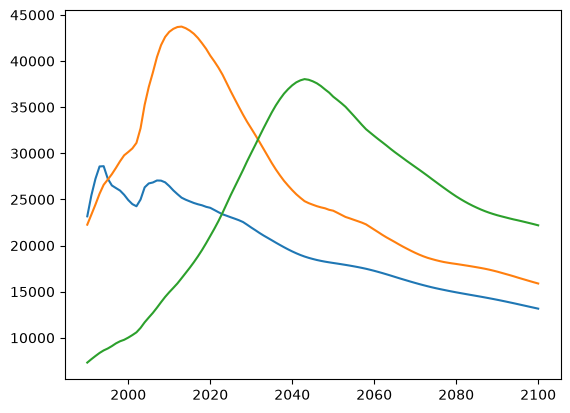

In [47]:
section = age_data[age_data['GEO_ID'] == 'W140000WOAD']
plt.plot(section['YR'], section['POP_YOUNG'])
plt.plot(section['YR'], section['POP_MIDDLE'])
plt.plot(section['YR'], section['POP_OLD'])

In [3]:
section = gdp_table[gdp_table['Country Code'] == 'US']
section

NameError: name 'gdp_table' is not defined

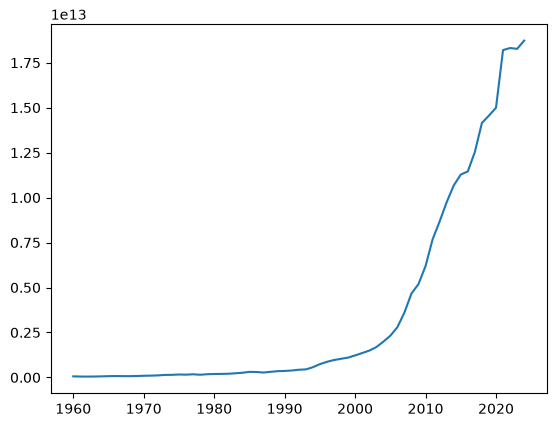

In [49]:
section = gdp_table[gdp_table['Country Code'] == 'CN']
plt.plot(section['YR'], section['GDP'])

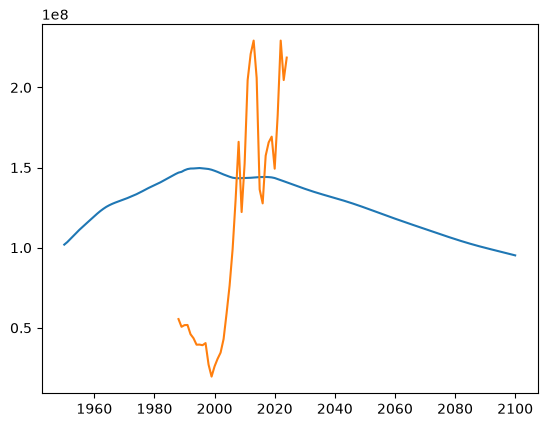

In [50]:
section = population_data[population_data['GEO_ID'] == 'W140000WORU']
# plt.plot(section['YR'], section['POP_YOUNG'])
# plt.plot(section['YR'], section['POP_MIDDLE'])
# plt.plot(section['YR'], section['POP_OLD'])
plt.plot(section['YR'], section['POP'])
section = gdp_table[gdp_table['Country Code'] == 'RU']
plt.plot(section['YR'], (section['GDP'])/1e4)

In [2]:
from load_data import run
general_data = run()

Retrieving Data from database...
Finished retrieval of data.


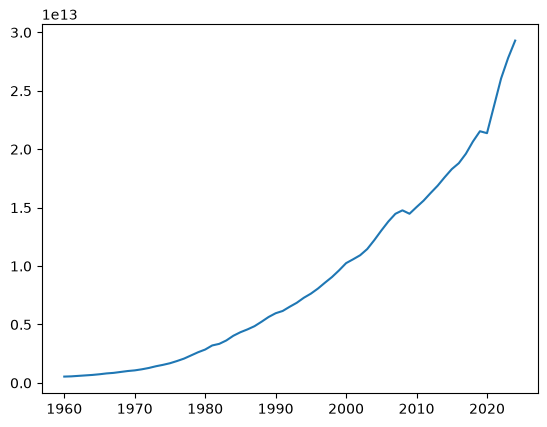

In [7]:
gdp_data = general_data.dropna(subset=['gdp'])
section = general_data[general_data['alpha3'] == 'USA']
plt.plot(section['yr'], (section['gdp']))
plt.show()

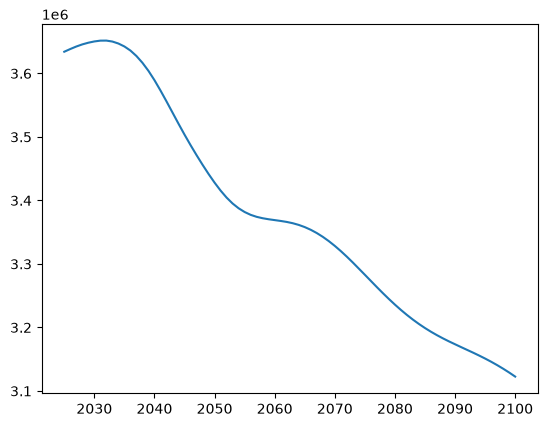

In [8]:
plt.plot(section['yr'], (section['births']))
plt.show()

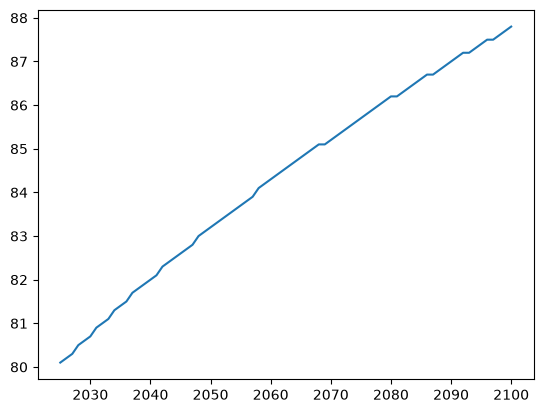

In [9]:
plt.plot(section['yr'], (section['e0']))
plt.show()

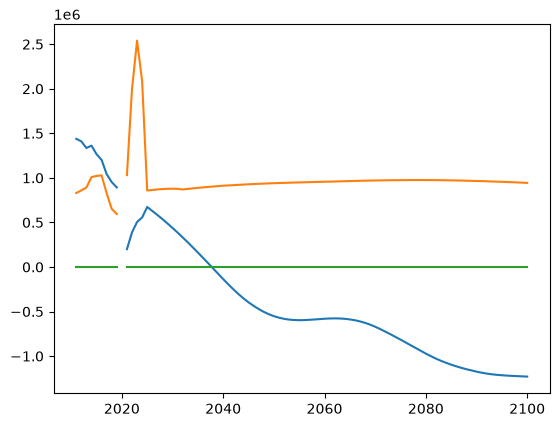

In [10]:
plt.plot(section['yr'], (section['natincr']))
plt.plot(section['yr'], (section['nim']))
plt.plot(section['yr'], (section['gr']))
plt.show()

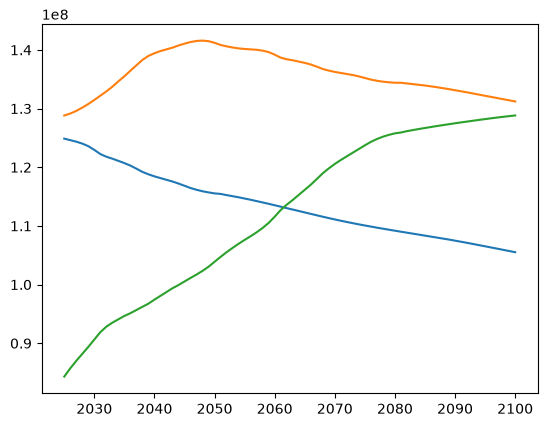

In [15]:
plt.plot(section['yr'], (section['pop_young']))
plt.plot(section['yr'], (section['pop_middle']))
plt.plot(section['yr'], (section['pop_old']))
plt.show()

In [12]:
country_data = general_data[general_data['alpha2'] == 'IN']

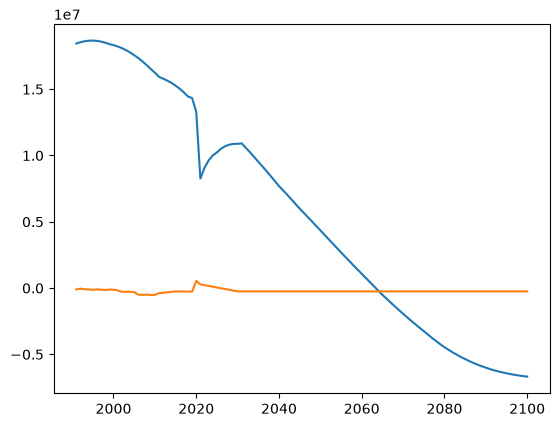

In [13]:
plt.plot(country_data['yr'], (country_data['natincr']))
plt.plot(country_data['yr'], (country_data['nim']))
plt.show()

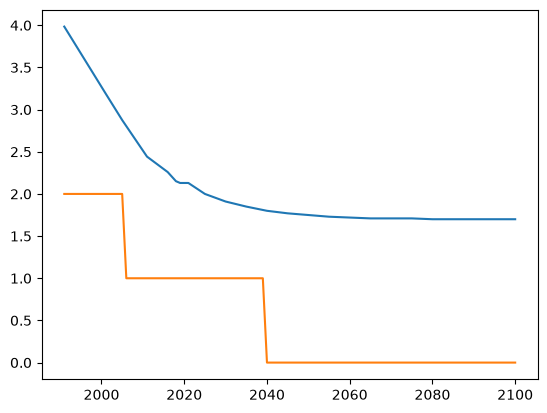

In [14]:
plt.plot(country_data['yr'], (country_data['tfr']))
plt.plot(country_data['yr'], (country_data['gr']))
plt.show()

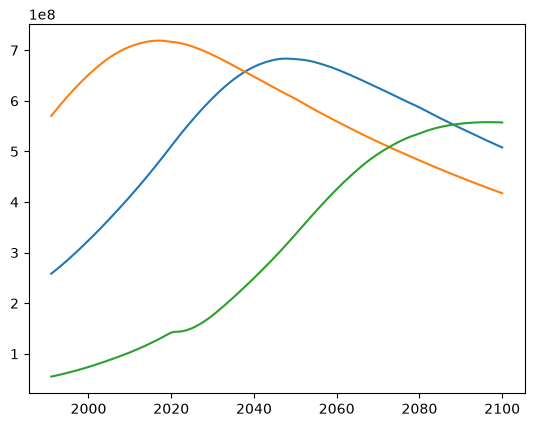

In [50]:
plt.plot(country_data['yr'], (country_data['pop_middle']))
plt.plot(country_data['yr'], (country_data['pop_young']))
plt.plot(country_data['yr'], (country_data['pop_old']))

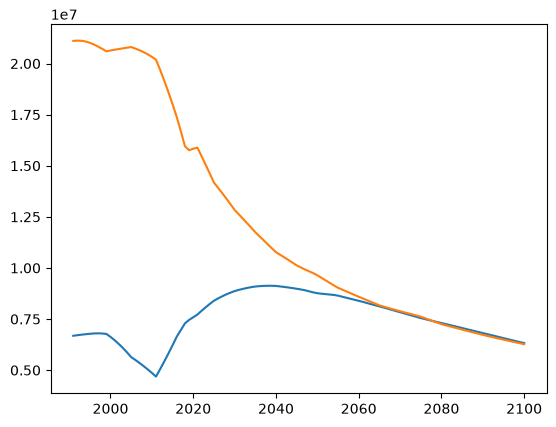

In [51]:
plt.plot(country_data['yr'], (country_data['births_middle']))
plt.plot(country_data['yr'], (country_data['births_young']))

In [64]:
country_data = general_data[(general_data['yr'] == 2000) & (general_data['alpha3'] == 'AND')]
pop_country_data = country_data[['yr', 'pop_young', 'pop_middle', 'pop_old']]
pop_country_data.dropna(inplace=True)
pop_country_data

,yr,pop_young,pop_middle,pop_old
50,2000,24933.0,30143.0,10023.0


In [66]:
pop_long = pop_country_data.melt(
    value_vars=['pop_young', 'pop_middle', 'pop_old'],
    var_name='age_group',
    value_name='population',
)
pop_long

,age_group,population
0,pop_young,24933.0
1,pop_middle,30143.0
2,pop_old,10023.0


In [2]:
from data_process import AMALGAMATED_DATA, bin_lat
country_info = bin_lat()
country_info


Retrieving Data from database...
Finished retrieval of data.


,Alpha-2 code,Latitude (average),alpha2,sphere
0,AF,33.000000,AF,South
1,AX,60.116667,AX,South
2,AL,41.000000,AL,South
3,DZ,28.000000,DZ,North
4,AS,-14.333300,AS,North
...,...,...,...,...
257,WF,-13.300000,WF,North
258,EH,24.500000,EH,North
259,YE,15.000000,YE,North
260,ZM,-15.000000,ZM,North


In [3]:
df = AMALGAMATED_DATA[AMALGAMATED_DATA['yr'].between(2010, 2023)]
df

,alpha2,alpha3,area,country_name,yr,tfr,imr,e0,gr,births,...,natincr,deaths,gdp,pop,pop_dens,pop_young,pop_middle,pop_old,births_young,births_middle
60,AD,AND,468,Andorra,2010,1.3391,3.60,82.88,0.0,848.0,...,350.0,498.0,3.449926e+09,84563,180.7,26452,43168,14943,300,548
61,AD,AND,468,Andorra,2011,1.3482,3.59,82.89,0.0,819.0,...,301.0,518.0,3.629134e+09,84888,181.4,25979,43494,15415,281,538
62,AD,AND,468,Andorra,2012,1.3572,3.59,82.91,0.0,788.0,...,250.0,538.0,3.188653e+09,85164,182.0,25574,43691,15899,266,522
63,AD,AND,468,Andorra,2013,1.3662,3.58,82.92,0.0,758.0,...,200.0,558.0,3.193513e+09,85389,182.5,25194,43738,16457,252,506
64,AD,AND,468,Andorra,2014,1.3752,3.58,82.94,0.0,725.0,...,150.0,575.0,3.271686e+09,85563,182.8,24974,43566,17023,246,479
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34195,ZW,ZWE,386847,Zimbabwe,2019,3.6667,37.86,64.47,2.0,487406.0,...,369282.0,118124.0,3.336063e+10,15433591,39.9,10295131,4271843,866617,336013,151393
34196,ZW,ZWE,386847,Zimbabwe,2020,3.6500,36.46,65.46,2.0,492853.0,...,378363.0,114490.0,3.197975e+10,15787762,40.8,10489984,4410252,887526,338506,154347
34197,ZW,ZWE,386847,Zimbabwe,2021,3.6040,35.50,65.29,2.0,494196.0,...,376507.0,117689.0,4.128785e+10,16138294,41.7,10681062,4549338,907894,338099,156097
34198,ZW,ZWE,386847,Zimbabwe,2022,3.5580,34.57,66.43,2.0,494608.0,...,381943.0,112665.0,4.075759e+10,16481694,42.6,10863910,4688381,929403,337700,156908


In [4]:
binned_df = df.merge(country_info, on='alpha2', how='left')
binned_df

,alpha2,alpha3,area,country_name,yr,tfr,imr,e0,gr,births,...,pop,pop_dens,pop_young,pop_middle,pop_old,births_young,births_middle,Alpha-2 code,Latitude (average),sphere
0,AD,AND,468,Andorra,2010,1.3391,3.60,82.88,0.0,848.0,...,84563,180.7,26452,43168,14943,300,548,AD,42.5,South
1,AD,AND,468,Andorra,2011,1.3482,3.59,82.89,0.0,819.0,...,84888,181.4,25979,43494,15415,281,538,AD,42.5,South
2,AD,AND,468,Andorra,2012,1.3572,3.59,82.91,0.0,788.0,...,85164,182.0,25574,43691,15899,266,522,AD,42.5,South
3,AD,AND,468,Andorra,2013,1.3662,3.58,82.92,0.0,758.0,...,85389,182.5,25194,43738,16457,252,506,AD,42.5,South
4,AD,AND,468,Andorra,2014,1.3752,3.58,82.94,0.0,725.0,...,85563,182.8,24974,43566,17023,246,479,AD,42.5,South
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3327,ZW,ZWE,386847,Zimbabwe,2019,3.6667,37.86,64.47,2.0,487406.0,...,15433591,39.9,10295131,4271843,866617,336013,151393,ZW,-20.0,North
3328,ZW,ZWE,386847,Zimbabwe,2020,3.6500,36.46,65.46,2.0,492853.0,...,15787762,40.8,10489984,4410252,887526,338506,154347,ZW,-20.0,North
3329,ZW,ZWE,386847,Zimbabwe,2021,3.6040,35.50,65.29,2.0,494196.0,...,16138294,41.7,10681062,4549338,907894,338099,156097,ZW,-20.0,North
3330,ZW,ZWE,386847,Zimbabwe,2022,3.5580,34.57,66.43,2.0,494608.0,...,16481694,42.6,10863910,4688381,929403,337700,156908,ZW,-20.0,North
